In [56]:
#필요한 도구 가져오기
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures    # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [57]:
# 정답 준비
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [58]:
#입력데이터 읽어오기
df =pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [59]:
#학습데이터,테스트 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(df,perch_weight)

In [60]:
#polynomialFeatures 다항 특성 셍성 ,degree 추가, 정규화 작업
poly = PolynomialFeatures(degree=7,include_bias=False)
poly.fit(train_data)
train_poly= poly.transform(train_data)
test_poly= poly.transform(test_data)

In [61]:
print(poly.get_feature_names_out())

['length' ' height' ' width' 'length^2' 'length  height' 'length  width'
 ' height^2' ' height  width' ' width^2' 'length^3' 'length^2  height'
 'length^2  width' 'length  height^2' 'length  height  width'
 'length  width^2' ' height^3' ' height^2  width' ' height  width^2'
 ' width^3' 'length^4' 'length^3  height' 'length^3  width'
 'length^2  height^2' 'length^2  height  width' 'length^2  width^2'
 'length  height^3' 'length  height^2  width' 'length  height  width^2'
 'length  width^3' ' height^4' ' height^3  width' ' height^2  width^2'
 ' height  width^3' ' width^4' 'length^5' 'length^4  height'
 'length^4  width' 'length^3  height^2' 'length^3  height  width'
 'length^3  width^2' 'length^2  height^3' 'length^2  height^2  width'
 'length^2  height  width^2' 'length^2  width^3' 'length  height^4'
 'length  height^3  width' 'length  height^2  width^2'
 'length  height  width^3' 'length  width^4' ' height^5'
 ' height^4  width' ' height^3  width^2' ' height^2  width^3'
 ' height  widt

In [62]:
#표준화, 릿지 규제 적용
ss =StandardScaler()
ss.fit(train_poly)
train_scaled= ss.transform(train_poly)
test_scaled= ss.transform(test_poly)

In [63]:
#데이터 학습
lr= LinearRegression()
lr.fit(train_poly,train_label)
score= lr.score(train_poly,train_label)
score2=lr.score(test_poly,test_label)
print(score)
print(score2)

0.9942991001193972
0.8877015000508713


In [64]:
#데이터 학습
#모델 학습시키기 , 릿지 규제 사용/ alpha값 변경 후 데이터 학습 확인
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score= []
test_score= []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    #모델 평가
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)

In [65]:
#데이터 예측
predict = ridge.predict(test_scaled)
print("예측무게:",predict)
#정확도
print('train정확도 : ',score)
print('test정확도 : ',score2)

예측무게: [ 139.27957811  141.69761209  120.37038719  964.03798823  154.10747109
  803.99991646  660.03654013  148.07552173  144.09099529  595.11941827
  533.24863681  209.01270106  861.19017643 1250.89213516]
train정확도 :  0.9787008149443243
test정확도 :  0.9486771108870828


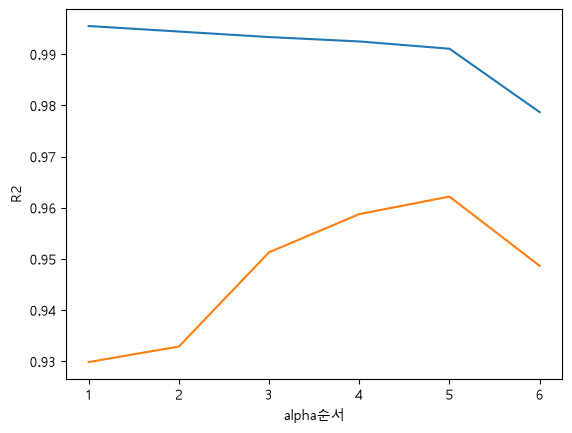

In [66]:
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel("alpha순서")
plt.ylabel("R2")
plt.show()